<a href="https://colab.research.google.com/github/Lalesh2005/computer_vision/blob/main/simple_neural_network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import tensorflow as tf

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_CHANNELS = 3

CLASS_NAMES = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]

In [2]:
def read_and_decode(filename, resize_dims):
    # 1. Read the raw file
    img_bytes = tf.io.read_file(filename)
    # 2. Decode image data
    img = tf.image.decode_jpeg(img_bytes, channels=IMG_CHANNELS)
    # 3. Convert pixel values to floats in [0, 1]
    img = tf.image.convert_image_dtype(img, tf.float32)
    # 4. Resize the image to match desired dimensions
    img = tf.image.resize(img, resize_dims)
    return img

In [3]:
def parse_csvline(csv_line):
    # record_defaults specify the data types for each column
    record_default = ["", ""]
    filename, label_string = tf.io.decode_csv(csv_line, record_default)

    # Load the image
    img = read_and_decode(filename, [IMG_HEIGHT, IMG_WIDTH])

    # Convert label string to integer based on the CLASS_NAMES index
    label = tf.argmax(tf.math.equal(CLASS_NAMES, label_string))
    return img, label

In [4]:
# Download the flower photos dataset (the old gs://cloud-ml-data CSV links are
# no longer publicly readable, so we use TensorFlow's official public dataset instead)
import pathlib

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
# untar=True (the classic pattern used in the official TF tutorials) reliably
# returns the path to the extracted "flower_photos" folder, unlike relying on
# archive_path.with_suffix(''), which can point to the wrong location.
data_dir = tf.keras.utils.get_file("flower_photos", origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir)

# Build a list of (filepath, label) pairs by scanning the extracted folder
# recursively -- more robust than assuming an exact directory layout.
all_files = []
all_labels = []
for img_path in data_dir.rglob("*.jpg"):
    class_name = img_path.parent.name
    if class_name in CLASS_NAMES:
        all_files.append(str(img_path))
        all_labels.append(class_name)

print(f"Found {len(all_files)} images across {len(CLASS_NAMES)} classes")
assert len(all_files) > 0, f"No images found under {data_dir}. Check the extracted folder structure."

# Shuffle and split into train (80%) / eval (20%) sets
import random
combined = list(zip(all_files, all_labels))
random.seed(42)
random.shuffle(combined)

split_idx = int(0.8 * len(combined))
train_files, train_labels = zip(*combined[:split_idx])
eval_files, eval_labels = zip(*combined[split_idx:])

def make_dataset(files, labels):
    files_ds = tf.data.Dataset.from_tensor_slices(list(files))
    labels_ds = tf.data.Dataset.from_tensor_slices(list(labels))
    ds = tf.data.Dataset.zip((files_ds, labels_ds))

    def _load(filename, label_string):
        img = read_and_decode(filename, [IMG_HEIGHT, IMG_WIDTH])
        label = tf.argmax(tf.math.equal(CLASS_NAMES, label_string))
        return img, label

    return (
        ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE)
          .batch(16)
          .prefetch(tf.data.AUTOTUNE)
    )

train_dataset = make_dataset(train_files, train_labels)
eval_dataset = make_dataset(eval_files, eval_labels)

228813984/228813984 ━━━━━━━━━━━━━━━━━━━━ 12s 0us/step
Found 3670 images across 5 classes


In [5]:
for image_batch, label_batch in train_dataset.take(3):
    print("Image batch shape:", image_batch.shape)
    print("Label batch shape:", label_batch.shape)
    print("Labels:", label_batch.numpy())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Labels: [4 3 2 0 2 2 3 4 3 2 3 0 4 3 1 4]
Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Labels: [4 2 0 3 3 3 1 4 0 2 4 4 0 0 0 2]
Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Labels: [4 3 1 3 3 4 0 0 3 2 0 2 2 4 2 4]


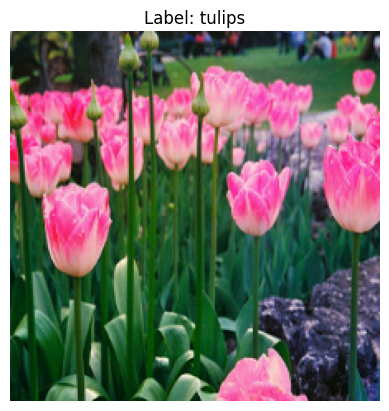

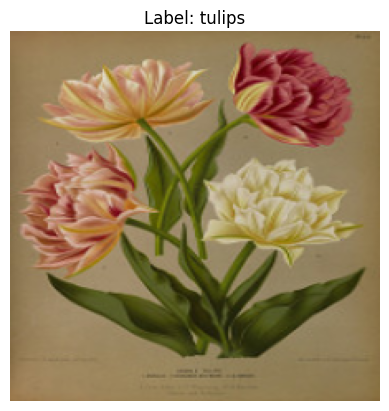

In [6]:
import matplotlib.pyplot as plt
for image_batch,label_batch in train_dataset.take(2):
  #Take the first image from the batch
  first_image = image_batch[0]
  first_label= label_batch[0]

  #convert teansor to numpy array
  plt.imshow(first_image.numpy())
  plt.title(f"Label: {CLASS_NAMES[first_label]}")
  plt.axis('off')
  plt.show()

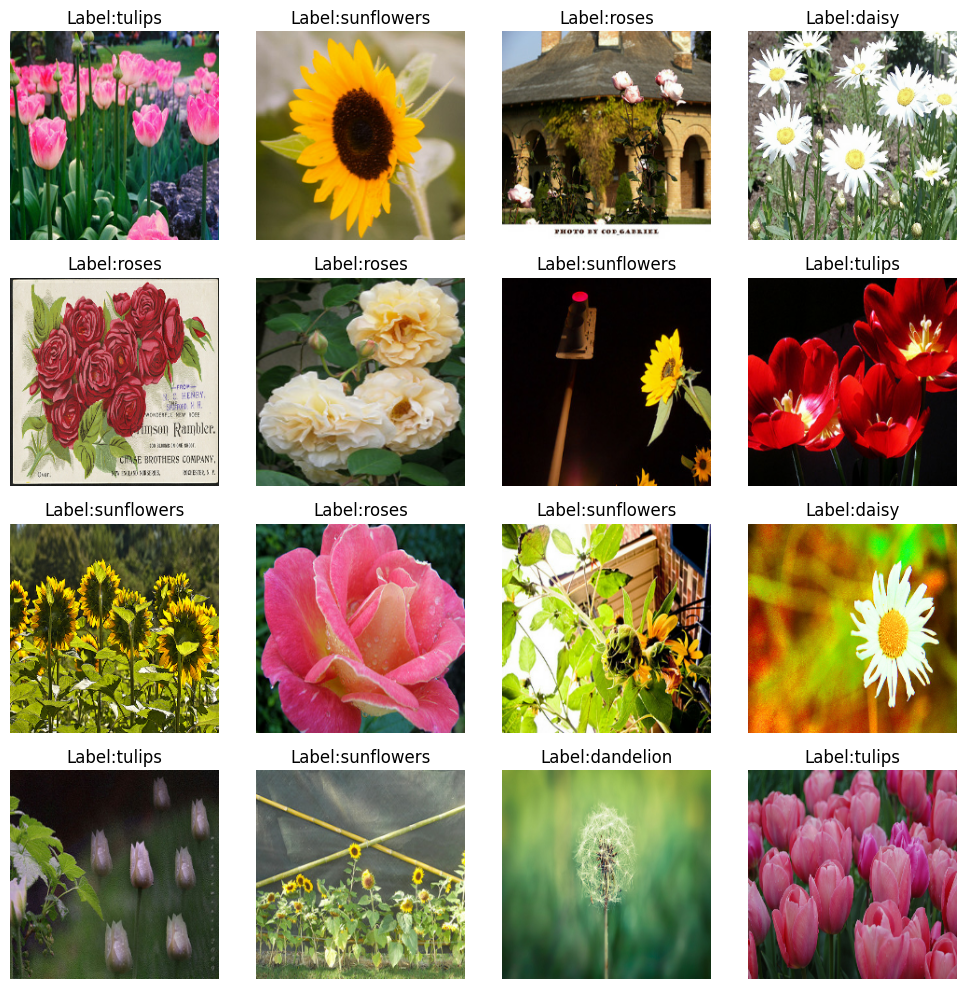

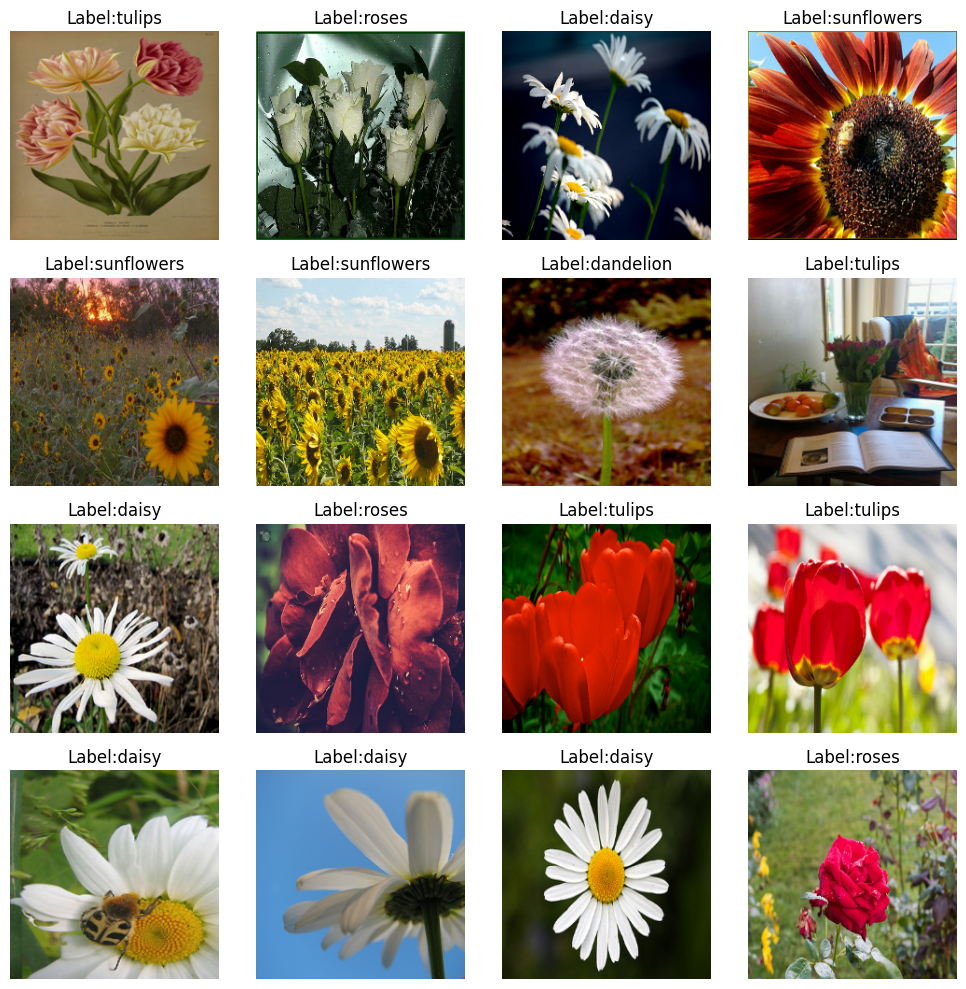

In [7]:
import matplotlib.pyplot as plt
# Take  one batch fromthe dataset
for image_batch,label_batch in train_dataset.take(2):
  fig,axes=plt.subplots(4,4,figsize=(10,10)) # create a 4*4 gird
  for i in range(16): # Loop over the first 16 image
    ax=axes[i // 4,i%4] # determine the grid positions
    ax.imshow(image_batch[i].numpy()) #convert tensor to numpy arr
    ax.set_title(f"Label:{CLASS_NAMES[label_batch[i]]}")
    ax.axis("off") ## Hide axes
  plt.tight_layout()
  plt.show()

In [8]:
# !pip install tensorflow

In [9]:
import tensorflow as tf

IMG_HEIGHT = 224
IMG_WIDTH = 224
IMG_CHANNELS = 3

CLASS_NAMES = ["daisy", "dandelion", "roses", "sunflowers", "tulips"]

In [10]:
def read_and_decode(filename, resize_dims):
    # 1. Read the raw file
    img_bytes = tf.io.read_file(filename)
    # 2. Decode image data
    img = tf.image.decode_jpeg(img_bytes, channels=IMG_CHANNELS)
    # 3. Convert pixel values to floats in [0, 1]
    img = tf.image.convert_image_dtype(img, tf.float32)
    # 4. Resize the image to match desired dimensions
    img = tf.image.resize(img, resize_dims)
    return img

In [11]:
def parse_csvline(csv_line):
    # record_defaults specify the data types for each column
    record_default = ["", ""]
    filename, label_string = tf.io.decode_csv(csv_line, record_default)

    # Load the image
    img = read_and_decode(filename, [IMG_HEIGHT, IMG_WIDTH])

    # Convert label string to integer based on the CLASS_NAMES index
    label = tf.argmax(tf.math.equal(CLASS_NAMES, label_string))
    return img, label

In [12]:
# Download the flower photos dataset (the old gs://cloud-ml-data CSV links are
# no longer publicly readable, so we use TensorFlow's official public dataset instead)
import pathlib

dataset_url = "https://storage.googleapis.com/download.tensorflow.org/example_images/flower_photos.tgz"
# untar=True (the classic pattern used in the official TF tutorials) reliably
# returns the path to the extracted "flower_photos" folder, unlike relying on
# archive_path.with_suffix(''), which can point to the wrong location.
data_dir = tf.keras.utils.get_file("flower_photos", origin=dataset_url, untar=True)
data_dir = pathlib.Path(data_dir)

# Build a list of (filepath, label) pairs by scanning the extracted folder
# recursively -- more robust than assuming an exact directory layout.
all_files = []
all_labels = []
for img_path in data_dir.rglob("*.jpg"):
    class_name = img_path.parent.name
    if class_name in CLASS_NAMES:
        all_files.append(str(img_path))
        all_labels.append(class_name)

print(f"Found {len(all_files)} images across {len(CLASS_NAMES)} classes")
assert len(all_files) > 0, f"No images found under {data_dir}. Check the extracted folder structure."

# Shuffle and split into train (80%) / eval (20%) sets
import random
combined = list(zip(all_files, all_labels))
random.seed(42)
random.shuffle(combined)

split_idx = int(0.8 * len(combined))
train_files, train_labels = zip(*combined[:split_idx])
eval_files, eval_labels = zip(*combined[split_idx:])

def make_dataset(files, labels):
    files_ds = tf.data.Dataset.from_tensor_slices(list(files))
    labels_ds = tf.data.Dataset.from_tensor_slices(list(labels))
    ds = tf.data.Dataset.zip((files_ds, labels_ds))

    def _load(filename, label_string):
        img = read_and_decode(filename, [IMG_HEIGHT, IMG_WIDTH])
        label = tf.argmax(tf.math.equal(CLASS_NAMES, label_string))
        return img, label

    return (
        ds.map(_load, num_parallel_calls=tf.data.AUTOTUNE)
          .batch(16)
          .prefetch(tf.data.AUTOTUNE)
    )

train_dataset = make_dataset(train_files, train_labels)
eval_dataset = make_dataset(eval_files, eval_labels)

Found 3670 images across 5 classes


In [13]:
for image_batch, label_batch in train_dataset.take(3):
    print("Image batch shape:", image_batch.shape)
    print("Label batch shape:", label_batch.shape)
    print("Labels:", label_batch.numpy())

Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Labels: [4 3 2 0 2 2 3 4 3 2 3 0 4 3 1 4]
Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Labels: [4 2 0 3 3 3 1 4 0 2 4 4 0 0 0 2]
Image batch shape: (16, 224, 224, 3)
Label batch shape: (16,)
Labels: [4 3 1 3 3 4 0 0 3 2 0 2 2 4 2 4]


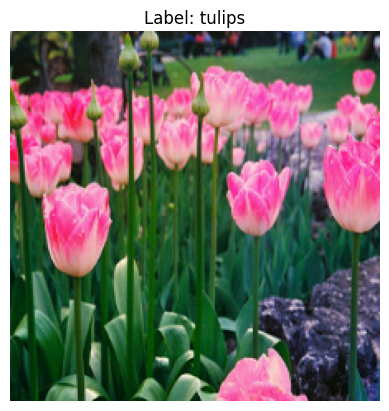

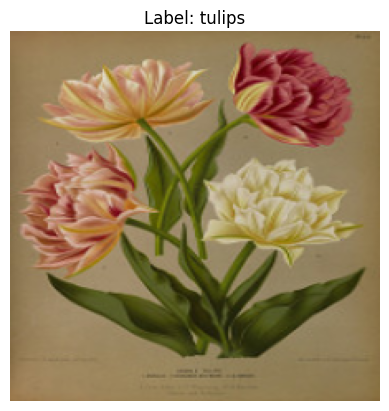

In [14]:
import matplotlib.pyplot as plt

for image_batch, label_batch in train_dataset.take(2):
    # Take the first image from the batch
    first_image = image_batch[0]
    first_label = label_batch[0]

    # Convert tensor to numpy array
    plt.imshow(first_image.numpy())
    plt.title(f"Label: {CLASS_NAMES[first_label]}")
    plt.axis('off')
    plt.show()

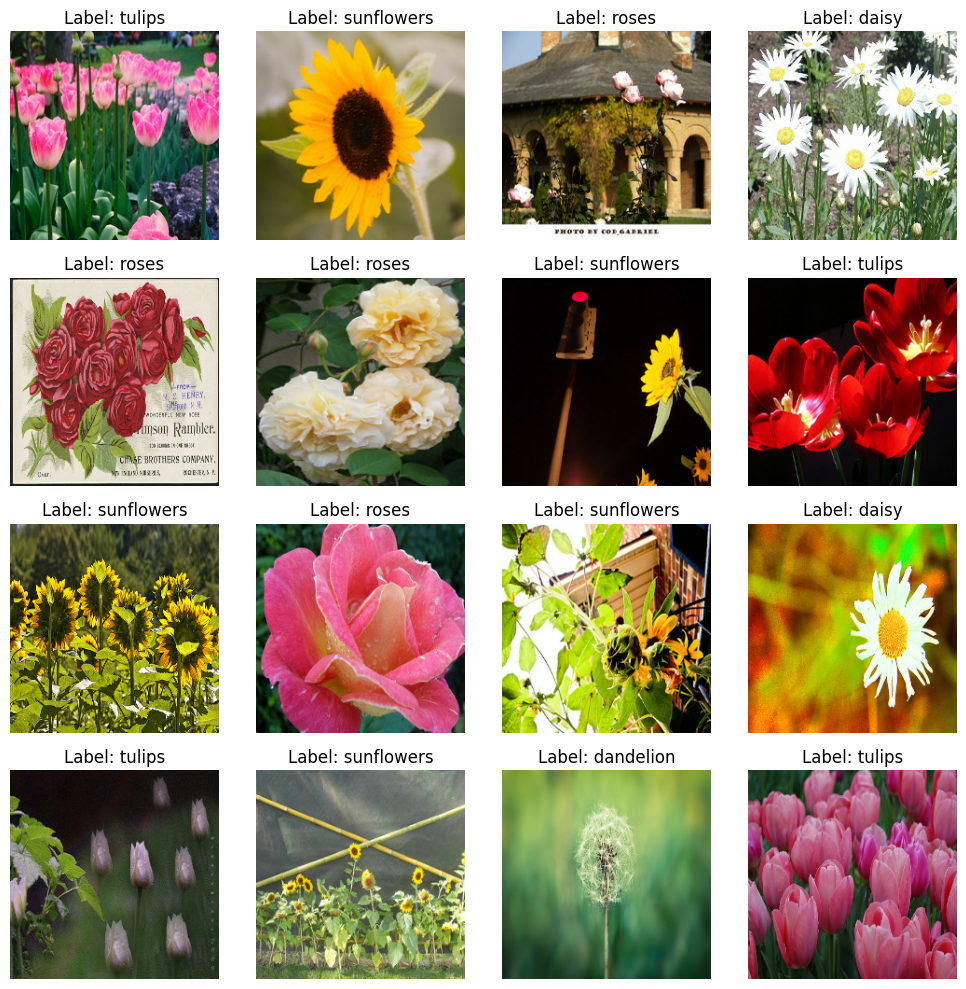

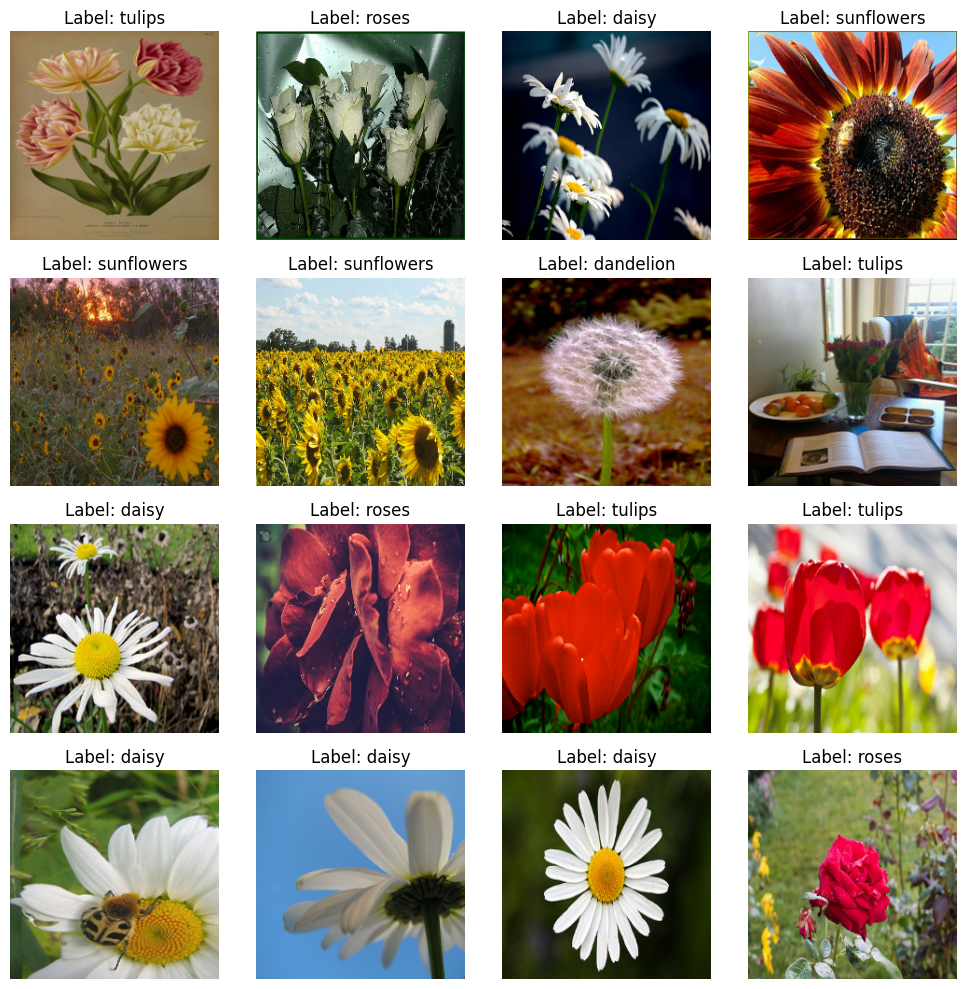

In [15]:
import matplotlib.pyplot as plt

# Take one batch from the dataset
for image_batch, label_batch in train_dataset.take(2):
    fig, axes = plt.subplots(4, 4, figsize=(10, 10))  # Create a 4x4 grid

    for i in range(16):  # Loop over the first 16 images
        ax = axes[i // 4, i % 4]  # Determine grid position
        ax.imshow(image_batch[i].numpy())  # Convert tensor to numpy array
        ax.set_title(f"Label: {CLASS_NAMES[label_batch[i]]}")
        ax.axis("off")  # Hide axes

    plt.tight_layout()
    plt.show()


In [16]:
from tensorflow import keras

model = keras.Sequential([
    keras.layers.Flatten(input_shape=(IMG_HEIGHT, IMG_WIDTH, IMG_CHANNELS)),
    keras.layers.Dense(len(CLASS_NAMES), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss=keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics=["accuracy"]
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [17]:
EPOCHS = 10

history = model.fit(
    train_dataset,
    validation_data=eval_dataset,
    epochs=EPOCHS
)

Epoch 1/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 10s 44ms/step - accuracy: 0.3471 - loss: 16.5597 - val_accuracy: 0.3556 - val_loss: 11.4829
Epoch 2/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.4128 - loss: 9.6315 - val_accuracy: 0.3351 - val_loss: 10.4355
Epoch 3/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 7s 37ms/step - accuracy: 0.4510 - loss: 9.5305 - val_accuracy: 0.3828 - val_loss: 20.0563
Epoch 4/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.4884 - loss: 8.7793 - val_accuracy: 0.3719 - val_loss: 12.8414
Epoch 5/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 6s 34ms/step - accuracy: 0.4850 - loss: 10.4526 - val_accuracy: 0.3624 - val_loss: 16.6681
Epoch 6/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 7s 40ms/step - accuracy: 0.5204 - loss: 10.3498 - val_accuracy: 0.3951 - val_loss: 13.9911
Epoch 7/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 7s 36ms/step - accuracy: 0.5841 - loss: 7.0792 - val_accuracy: 0.3406 - val_loss: 16.1409
Epoch 8/10
184/184 ━━━━━━━━━━━━━━━━━━━━ 9s 31ms/step - accuracy: 0.5630 - loss: 7.4497

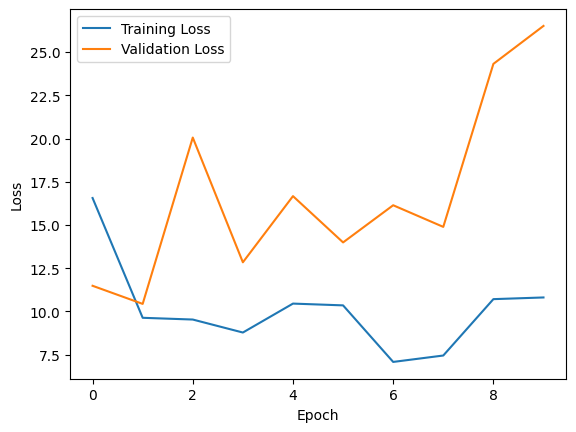

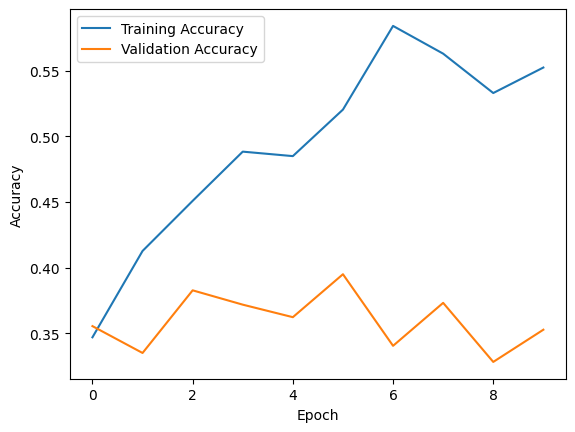

In [18]:
import matplotlib.pyplot as plt

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 168ms/step


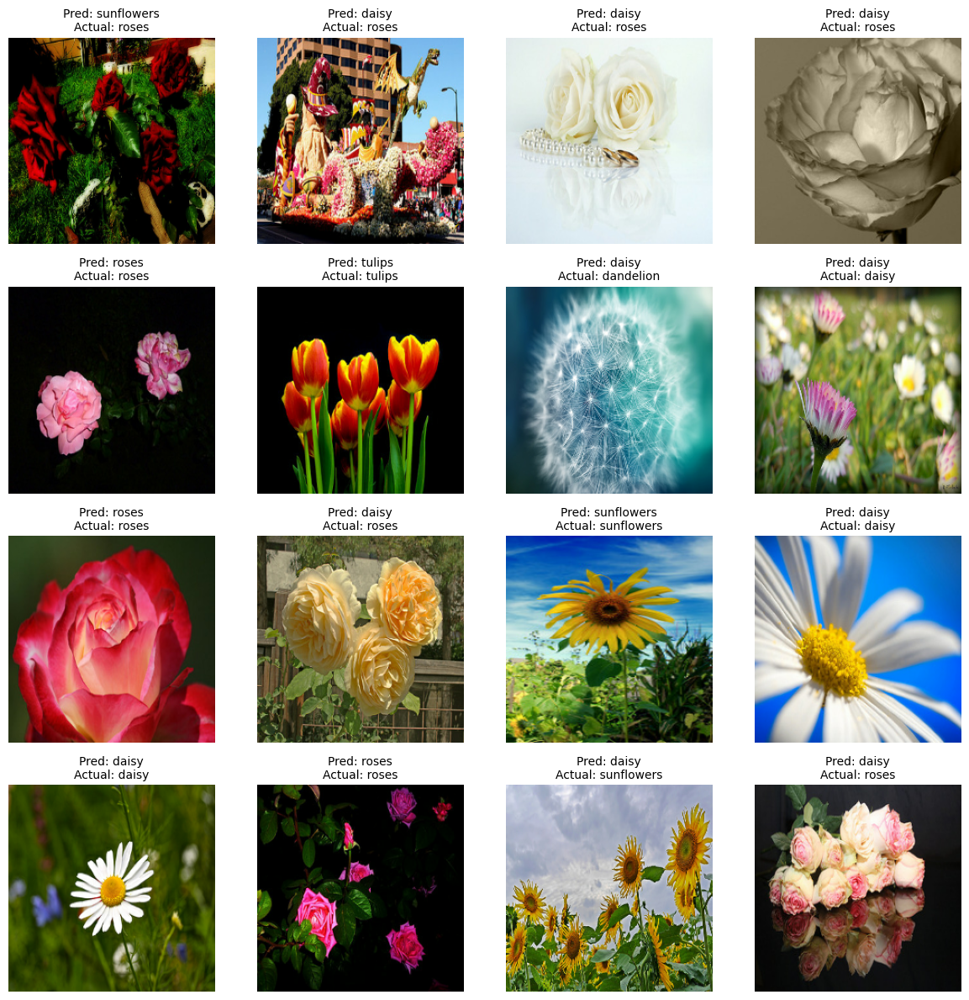

In [19]:
import numpy as np
import matplotlib.pyplot as plt
import math

# Take exactly one batch from the evaluation dataset
for images, labels in eval_dataset.take(1):
    # Get model predictions for this batch
    batch_predictions = model.predict(images)
    predicted_indices = np.argmax(batch_predictions, axis=1)

    # Number of images in this batch
    num_images = images.shape[0]

    # Configure how many images to display per row
    num_cols = 4
    num_rows = math.ceil(num_images / num_cols)

    # Create a figure with a suitable size
    plt.figure(figsize=(12, 3 * num_rows))

    for i in range(num_images):
        plt.subplot(num_rows, num_cols, i + 1)

        # Display the image
        plt.imshow(images[i].numpy())
        plt.axis('off')

        # Get predicted and actual class names
        pred_class = CLASS_NAMES[predicted_indices[i]]
        actual_class = CLASS_NAMES[labels[i].numpy()]

        # Show both predicted and actual labels as title
        plt.title(f"Pred: {pred_class}\nActual: {actual_class}", fontsize=10)

    # Adjust spacing to avoid overlapping titles, etc.
    plt.tight_layout()
    plt.show()